# Weekend 2 — the first real models

Last time you built the yardstick: **seasonal naive, MAE 4,780**. Today you try to beat it.

Two models, both about three lines each:

- **Holt-Winters** — a weighted average of the recent past that also knows winter is worse than
  summer. Recent weeks count more than old ones.
- **SARIMA** — the classical statistics answer. It learns from *how the series moves*: how much
  this week tends to follow last week, and how much this week tends to follow the same week a
  year ago.

You do not need the maths for either. You need to know what they assume and where they break.

**There is a trap in this notebook**, in Task 3. It is the single most common way people fool
themselves when comparing a model to a baseline, and you are going to walk into it deliberately
and then fix it.

## SETUP

`warnings` gets silenced because Holt-Winters prints a convergence warning on roughly a quarter
of these fits. **That is a real finding, not noise to hide** — we come back to it at the end. It
is silenced only so the output stays readable.

In [32]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

URL = ('https://raw.githubusercontent.com/cdcepi/FluSight-forecast-hub/'
       'main/target-data/target-hospital-admissions.csv')
raw = pd.read_csv(URL, parse_dates=['date'])
us = raw[raw['location'] == 'US'].sort_values('date').reset_index(drop=True)
print(len(us), 'weeks')

231 weeks


## YOUR TURN 1 — give the series a real time index

Last weekend you worked with a plain DataFrame and used `.shift(52)` to mean "a year ago".
That worked because you had checked every row was exactly 7 days apart.

The model libraries need more than that: they need to *know* the series is weekly. So convert it
into a pandas **Series indexed by date, with an explicit weekly frequency**.

Build `y`:
- index = the `date` column
- values = the `value` column
- then call `.asfreq('W-SAT')` on it — "weekly, on Saturdays"

Then print the length, the first and last date, and **how many missing values** there are.

*Why the missing-value check matters:* `asfreq` builds a complete weekly calendar and inserts
`NaN` for any week your data lacks. If your series had a hole, this is where it shows up — and
the models will refuse to fit. You should get **0 missing**, because you already verified there
are no gaps.

In [33]:
# your code here

y = us.set_index('date')['value'].asfreq('W-SAT')
print(len(y), y.index[0].date(), y.index[-1].date(), '|missing: ', y.isna().sum())

# --- hint ---
# y = us.set_index('date')['value'].asfreq('W-SAT')
# print(len(y), y.index[0].date(), y.index[-1].date(), '| missing:', y.isna().sum())

231 2022-02-05 2026-07-04 |missing:  0


## YOUR TURN 2 — fit Holt-Winters and look at it

Split the series in time: **everything except the last 52 weeks** to train on, **the last 52
weeks** to test against. Never shuffle — the test set must be the future.

Then fit Holt-Winters on the training part and forecast 52 weeks.

```python
model = ExponentialSmoothing(
    train,
    trend='add',              # allow a rising or falling level
    seasonal='add',           # allow a repeating yearly pattern
    seasonal_periods=52,      # the pattern repeats every 52 weeks
    initialization_method='estimated',
).fit()
forecast = model.forecast(52)
```

Then **plot the last ~2 years of training data, the actual test values, and your forecast** on
one chart so you can see what it did.

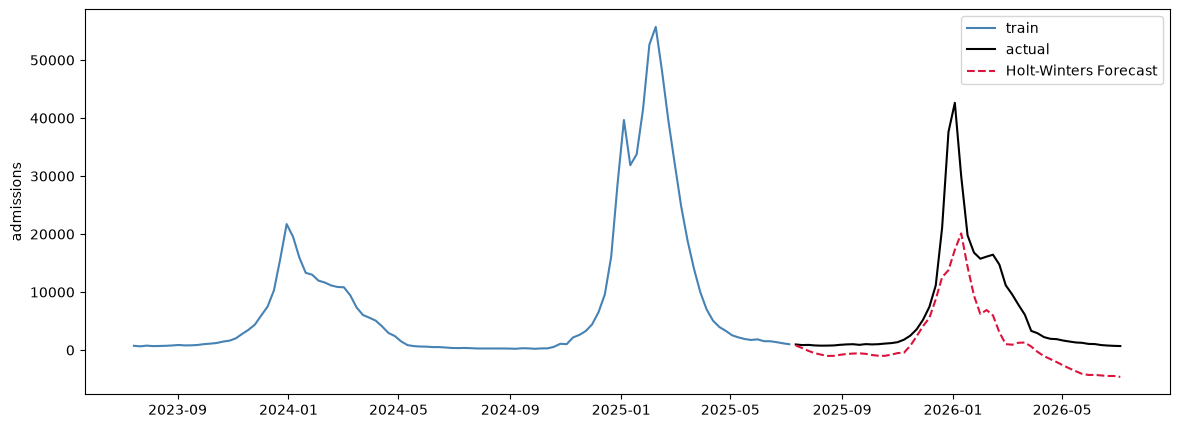

In [34]:
# your code here
train, test = y[:-52], y[-52:]
model = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=53, initialization_method='estimated').fit()
fc = model.forecast(52)

fig, ax = plt.subplots(figsize=(14,5))
ax.plot(train[-104:].index, train[-104:], label='train', color='steelblue')
ax.plot(test.index, test, label='actual', color='black')
ax.plot(fc.index, fc, label='Holt-Winters Forecast', color='crimson', ls='--')
ax.legend(); ax.set_ylabel('admissions'); plt.show()


# --- hint ---
# train, test = y[:-52], y[-52:]
# model = ExponentialSmoothing(train, trend='add', seasonal='add',
#                              seasonal_periods=52, initialization_method='estimated').fit()
# fc = model.forecast(52)
#
# fig, ax = plt.subplots(figsize=(14, 5))
# ax.plot(train[-104:].index, train[-104:], label='train', color='steelblue')
# ax.plot(test.index, test, label='actual', color='black')
# ax.plot(fc.index, fc, label='Holt-Winters forecast', color='crimson', ls='--')
# ax.legend(); ax.set_ylabel('admissions'); plt.show()

## YOUR TURN 3 — score it, and then find the trap

**Part A.** Compute the MAE of your Holt-Winters forecast against `test`.

**Part B.** Compare it to your baseline of **4,780** — and then stop, because that comparison is
wrong. Work out why before reading on.

**Part C.** Compute the seasonal-naive MAE **on these same 52 test weeks** and compare to that
instead. For each test week, the naive prediction is the value 52 weeks earlier — which you can
read straight out of `y`.

In [35]:
# your code here

mae_hw = (test-fc).abs().mean()
naive_on_test = y.shift(52).loc[test.index]
mae_naive_here = (test - naive_on_test).abs().mean()
print(f'Holt-Winters: {mae_hw:,.0f}')
print(f'naive (same 52 weeks): {mae_naive_here:,.0f}')
print(f'naive (full history) : 4,780   <-- NOT a valid comparison')

# --- hint ---
# mae_hw = (test - fc).abs().mean()
# naive_on_test = y.shift(52).loc[test.index]
# mae_naive_here = (test - naive_on_test).abs().mean()
# print(f'Holt-Winters : {mae_hw:,.0f}')
# print(f'naive (same 52 weeks): {mae_naive_here:,.0f}')
# print(f'naive (full history) : 4,780   <-- NOT a valid comparison')

Holt-Winters: 4,917
naive (same 52 weeks): 5,423
naive (full history) : 4,780   <-- NOT a valid comparison


### The trap, explained

**4,780 was measured over 179 weeks running from February 2023 to July 2026. Your model was
scored on 52 completely different weeks.** Comparing them measures which *period* was easier to
forecast, not which *method* is better.

This is the most common way people mislead themselves when reporting a portfolio result, and it
is invisible: both numbers are correct, the comparison is meaningless. Nobody catches it by
reading the code.

**And note which direction it went.** Scored against the right baseline your model looks *better*,
not worse. The wrong comparison is not "cheating" — it is arbitrary, and it can flatter you or rob
you. That is exactly why it has to be fixed rather than argued about.

**The rule: a baseline is only a baseline if it is scored on exactly the weeks your model was
scored on.** Recompute it every time the evaluation window changes.

There is also a second problem, and it is bigger. You forecast **52 weeks ahead from a single
starting point.** But the project promises forecasts **4 weeks ahead**, refreshed every week.
Those are completely different tasks, and one number from one lucky starting week is not evidence
about either. That is what the rest of the notebook fixes.

## Rolling-origin backtesting — what it is

A single train/test split answers *"how did this model do starting from one particular week?"*
Pick a different week and you get a different answer.

**Rolling origin** does it properly. Walk forward through the series, and at each week:

1. Pretend it is that week and you know nothing after it.
2. Refit the model on everything up to that point.
3. Forecast the next 4 weeks.
4. Record the error at each of horizon 1, 2, 3 and 4.

Then average over all the weeks. You get ~100 forecasts instead of one, and — the important part
— **you get the error separately for each horizon.**

That separation matters because **error grows with distance.** Next week is much easier to
predict than four weeks out, and a single blended number hides the difference. You are about to
see just how much it hides.

## YOUR TURN 4 — one cutoff, three forecasts

Write a function that does the work for **a single point in time**. The loop is provided
afterwards; this function is the part that matters.

```python
def forecast_one(hist, H=4):
    """hist = the series up to (not including) the forecast point.
    Return a dict of three arrays, each H values long."""
```

It should return forecasts from:

- `'naive'` — the seasonal-naive guess. For horizon `h`, that is the value **52 weeks before the
  week being predicted** — i.e. `hist.iloc[len(hist) + h - 52]` for `h` in `0..H-1`.
- `'hw'` — Holt-Winters, exactly as in Task 2 but fit on `hist` and forecasting `H` steps.
- `'sarima'` — `SARIMAX(hist, order=(1,1,1), seasonal_order=(1,0,0,52),
  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)`, then `.forecast(H)`.

**Wrap each model in `try`/`except`** and return `[np.nan]*H` on failure — a 97-iteration loop
that dies on iteration 60 and loses the work is a bad trade for two lines of defence.

**But `except Exception: return NaN` is dangerous, and this is the real lesson of the task.** It
catches *everything*, including your own typos. A misspelled argument name is a `TypeError`, the
`except` swallows it, and the backtest completes cleanly with that model silently `NaN` at every
single cutoff — no error, no warning, a full results table with a hole in it.

So **count the failures and print the first one**. A `try/except` you cannot see into is worse than
no `try/except` at all. The counter is set up in the cell below.

In [38]:
# A counter, so a failure is visible instead of silent. See the note below.
fails = {'hw': 0, 'sarima': 0}


def forecast_one(hist, H=4):
    out = {}
    out['naive'] = [hist.iloc[len(hist) + h - 52] for h in range(H)]
    for name, fit in [('hw', _fit_hw), ('sarima', _fit_sarima)]:
        try:
            out[name] = fit(hist, H)
        except Exception as e:
            fails[name] += 1
            if fails[name] == 1:          
                print(f'{name} first failure: {type(e).__name__}: {e}')
            out[name] = [np.nan] * H
    return out

def _fit_hw(hist, H):
    m = ExponentialSmoothing(hist, trend='add', seasonal='add', seasonal_periods=52,
                             initialization_method='estimated').fit()
    return m.forecast(H).values

def _fit_sarima(hist, H):
    m = SARIMAX(hist, order=(1, 1, 1), seasonal_order=(1, 0, 0, 52),
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return m.forecast(H).values


# --- hint ---
# def forecast_one(hist, H=4):
#     out = {}
#     out['naive'] = [hist.iloc[len(hist) + h - 52] for h in range(H)]
#     for name, fit in [('hw', _fit_hw), ('sarima', _fit_sarima)]:
#         try:
#             out[name] = fit(hist, H)
#         except Exception as e:
#             fails[name] += 1
#             if fails[name] == 1:          # report the FIRST failure, once
#                 print(f'{name} first failure: {type(e).__name__}: {e}')
#             out[name] = [np.nan] * H
#     return out
#
# def _fit_hw(hist, H):
#     m = ExponentialSmoothing(hist, trend='add', seasonal='add', seasonal_periods=52,
#                              initialization_method='estimated').fit()
#     return m.forecast(H).values
#
# def _fit_sarima(hist, H):
#     m = SARIMAX(hist, order=(1, 1, 1), seasonal_order=(1, 0, 0, 52),
#                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
#     return m.forecast(H).values

## SETUP — run the backtest

This calls your function once per week and collects the results. **It takes about 20–30 seconds**
— it is refitting both models ~97 times, which is the honest cost of doing this properly.

It starts at index 130 because Holt-Winters needs at least two full seasonal cycles (104 weeks)
before it can estimate a yearly pattern at all.

In [39]:
H, START = 4, 130
records = []

for cut in range(START, len(y) - H):
    hist = y.iloc[:cut]
    actual = y.iloc[cut:cut + H]
    f = forecast_one(hist, H)
    for h in range(H):
        records.append({
            'cutoff': y.index[cut - 1],
            'horizon': h + 1,
            'actual': actual.iloc[h],
            'naive': f['naive'][h],
            'hw': f['hw'][h],
            'sarima': f['sarima'][h],
        })

bt = pd.DataFrame(records)
print(f"{bt['cutoff'].nunique()} cutoffs, {bt['cutoff'].min().date()} to {bt['cutoff'].max().date()}")
bt.head()

97 cutoffs, 2024-07-27 to 2026-05-30


,cutoff,horizon,actual,naive,hw,sarima
0,2024-07-27,1,275.0,687.0,174.028172,194.757914
1,2024-07-27,2,275.0,705.0,142.142168,170.311644
2,2024-07-27,3,273.0,739.0,187.379130,164.482618
3,2024-07-27,4,274.0,795.0,446.360571,170.690035
4,2024-08-03,1,275.0,705.0,449.197630,320.539801


In [41]:
# SANITY CHECK — run this every time, before you look at any error number.
# A column that is entirely NaN means the model never fit, not that it did badly.
for m in ['naive', 'hw', 'sarima']:
    n_bad = bt[m].isna().sum()
    flag = '  <-- NOTHING FIT. Fix this before reading the results.' if n_bad == len(bt) else ''
    print(f'{m:8} {n_bad:>4} / {len(bt)} missing{flag}')
print('\nfit failures caught:', fails)

naive       0 / 388 missing
hw          0 / 388 missing
sarima      0 / 388 missing

fit failures caught: {'hw': 0, 'sarima': 0}


## YOUR TURN 5 — MAE by horizon

Produce a table with **one row per horizon (1–4)** and **one column per method** (`naive`, `hw`,
`sarima`), each cell the MAE at that horizon.

Then print the overall MAE for each method across all horizons.

*Approach: add an absolute-error column per method, then `groupby('horizon')` and take the mean.
There are neater ways; any way that gets the numbers is fine.*

In [42]:
# your code here
for m in ['naive', 'hw', 'sarima']:
    bt[f'ae_{m}'] = (bt['actual']-bt[m]).abs()
by_h = bt.groupby('horizon')[['ae_naive', 'ae_hw', 'ae_sarima']].mean().round(0)
print(by_h)
print()
print(bt[['ae_naive', 'ae_hw', 'ae_sarima']].mean().round(0))

# --- hint ---
# for m in ['naive', 'hw', 'sarima']:
#     bt[f'ae_{m}'] = (bt['actual'] - bt[m]).abs()
# by_h = bt.groupby('horizon')[['ae_naive', 'ae_hw', 'ae_sarima']].mean().round(0)
# print(by_h)
# print()
# print(bt[['ae_naive', 'ae_hw', 'ae_sarima']].mean().round(0))

         ae_naive   ae_hw  ae_sarima
horizon                             
1          6321.0  1661.0     1597.0
2          6323.0  3877.0     3544.0
3          6325.0  6398.0     4988.0
4          6324.0  8783.0     5992.0

ae_naive     6323.0
ae_hw        5180.0
ae_sarima    4030.0
dtype: float64


## Read your table before moving on

Three things should be visible. Check each one:

**1. The naive row barely changes across horizons.** Look at `ae_naive` at h=1 versus h=4 —
nearly identical. Why? Because "same week last year" doesn't care how far ahead you are. It
looks up a value from a year ago either way. **The baseline has no horizon.**

**2. Both real models get worse as the horizon grows** — and steeply. This is the single most
important fact about forecasting, and now you have measured it rather than been told it.

**3. Look at where Holt-Winters sits at horizon 3 and 4.** Compare it to naive at those same
horizons, carefully.

That third one is the finding of the day. Write down what you see:

**What I found:**
Naive barely changed across the horizons, holt-winters changed the most and ended up being highest by horizon 4 on holt-winters. 


## YOUR TURN 6 — the honest comparison

Now state the result the way it would go on a resume. For **SARIMA specifically**, at each
horizon, compute the **percentage improvement over naive scored on the same weeks**:

```
improvement = 100 * (1 - mae_sarima / mae_naive)
```

Print it per horizon, and once overall.

**This is the number the whole project reports.** Not "my MAE was X" — that means nothing on its
own. "X% better than seasonal naive, backtested at rolling origins over ~97 weeks, reported per
horizon" is a claim a forecaster can check.

In [43]:
# your code here
imp = 100 * (1 - by_h['ae_sarima']/by_h['ae_naive'])
for h,v in imp.items():
    print(f'horizon {h}: SARIMA is {v:.0f}% better than naive')
overall = 100 * (1 - bt['ae_sarima'].mean()/bt['ae_naive'].mean())
print(f'\noverall: {overall:.0f}%')


# --- hint ---
# imp = 100 * (1 - by_h['ae_sarima'] / by_h['ae_naive'])
# for h, v in imp.items():
#     print(f'horizon {h}: SARIMA is {v:.0f}% better than naive')
# overall = 100 * (1 - bt['ae_sarima'].mean() / bt['ae_naive'].mean())
# print(f'\noverall: {overall:.0f}%')

horizon 1: SARIMA is 75% better than naive
horizon 2: SARIMA is 44% better than naive
horizon 3: SARIMA is 21% better than naive
horizon 4: SARIMA is 5% better than naive

overall: 36%


## Record the result

| Method | h=1 | h=2 | h=3 | h=4 | overall |
|---|---|---|---|---|---|
| seasonal naive | 6321.0| 6323.0| 6325.0| 6324.0|6323.0 |
| Holt-Winters | 1661.0| 3877.0|6398.0 |8783.0 |5180.0 |
| SARIMA |1597.0 |3544.0 |4988.0 |5992.0 |4030.0 |

| | |
|---|---|
| Cutoffs backtested | |
| Period | |
| **SARIMA vs naive, overall** | 36%|
| **SARIMA vs naive, h=4** |5% |
| Date run |2026-09-06 |

## About those convergence warnings

Holt-Winters hit a convergence warning on roughly a quarter of the fits — about 24 of the 97.
None of them *failed*: every one returned a forecast. That is worth being able to talk about
rather than hiding behind `filterwarnings`.

It means the optimiser could not find stable values for the level, trend and seasonal terms — and
the reason is the thing you found last weekend. **Fitting 52 seasonal parameters from four
cycles is asking a lot from very little data**, especially when those four cycles differ in both
height and timing. The model has one seasonal shape to offer and the data does not have one.

Notice it did not fail loudly. It returned a forecast every time. This is why the backtest
exists: the numbers tell you the model is unreliable at longer horizons even though nothing
crashed.

---

## Done

You have a real result: a model, backtested honestly, reported per horizon, measured against a
baseline scored on the same weeks.

**Not yet, deliberately:** every number here is a single line — a point forecast. The project
needs *intervals*, because a hospital staffs to an upper quantile, not to the mean. That is
weekend 3, and it is the part that makes this project worth putting on a resume.